# LAB 07 — Transformer Architecture (IMDb)
Từ Self-Attention (LAB 06) tới Transformer Encoder: Multi-Head Attention + Positional Encoding + FFN + Residual/LayerNorm.
Notebook này chạy: core check (shape), Exp 1 (positional encoding + permutation), Exp 2 (số head), Exp 3 (head diversity),
Exp 4 (Transformer vs LSTM), Exp 5 (sequence length), Exp 6 (pooling), Application, Error analysis.
Mọi run được cache trong `.cache/` (xóa thư mục để train lại từ đầu).

In [1]:
import os, time, pickle, warnings
import numpy as np, pandas as pd, torch
import matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings("ignore")

import preprocessing as pp
import positional_encoding as pe_mod
import transformer_block as tb
import transformer_model as tm

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("torch", torch.__version__, "| device:", tm.DEVICE, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
CACHE = ".cache"; os.makedirs(CACHE, exist_ok=True)

torch 2.14.1+cu126 | device: cuda NVIDIA GeForce RTX 3050 6GB Laptop GPU


## 0. Core check — Transformer block tự ghép: shape và đối chiếu với `nn.TransformerEncoderLayer`

In [2]:
shp = tb.shape_table(B=8, T=100, d_model=128, n_heads=4, d_ff=512)
pd.DataFrame({"tensor": list(shp), "shape": [str(v) for v in shp.values()]})

,tensor,shape
0,X,"(8, 100, 128)"
1,Q,"(8, 4, 100, 32)"
2,K,"(8, 4, 100, 32)"
3,V,"(8, 4, 100, 32)"
4,Attention scores,"(8, 4, 100, 100)"
5,Attention weights A,"(8, 4, 100, 100)"
6,Head outputs (A V),"(8, 4, 100, 32)"
7,Concat heads,"(8, 100, 128)"
8,Attention output (after W_O),"(8, 100, 128)"
9,FFN (hidden d_ff),"(8, 100, 512)"


In [3]:
diff = tb.check_against_torch()
print(f"max |TransformerBlock (tự viết) - nn.TransformerEncoderLayer| = {diff:.2e}  (cùng trọng số, có padding mask)")
x = torch.randn(2, 6, 16); m = torch.tensor([[1,1,1,1,0,0],[1]*6], dtype=torch.bool)
_, A = tb.TransformerBlock(16, 2, 32).eval()(x, m, return_attention=True)
print("tổng mỗi hàng attention = 1:", torch.allclose(A.sum(-1), torch.ones(2, 2, 6)), "| weight lên <pad>:", A[0, :, :, 4:].abs().max().item())
blk = tb.TransformerBlock(128, 4, 512)
print("params / block:", sum(p.numel() for p in blk.parameters()), "= MHSA", sum(p.numel() for p in blk.attn.parameters()),
      "+ FFN", sum(p.numel() for p in blk.ffn.parameters()), "+ 2 LayerNorm", 2 * sum(p.numel() for p in blk.norm1.parameters()))

max |TransformerBlock (tự viết) - nn.TransformerEncoderLayer| = 3.58e-07  (cùng trọng số, có padding mask)
tổng mỗi hàng attention = 1: True | weight lên <pad>: 0.0
params / block: 198272 = MHSA 66048 + FFN 131712 + 2 LayerNorm 512


## 1. Experiment 1 — Positional encoding và permutation experiment

PE (d=4), pos = 0, 1, 2:
 [[ 0.      1.      0.      1.    ]
 [ 0.8415  0.5403  0.01    1.    ]
 [ 0.9093 -0.4161  0.02    0.9998]]


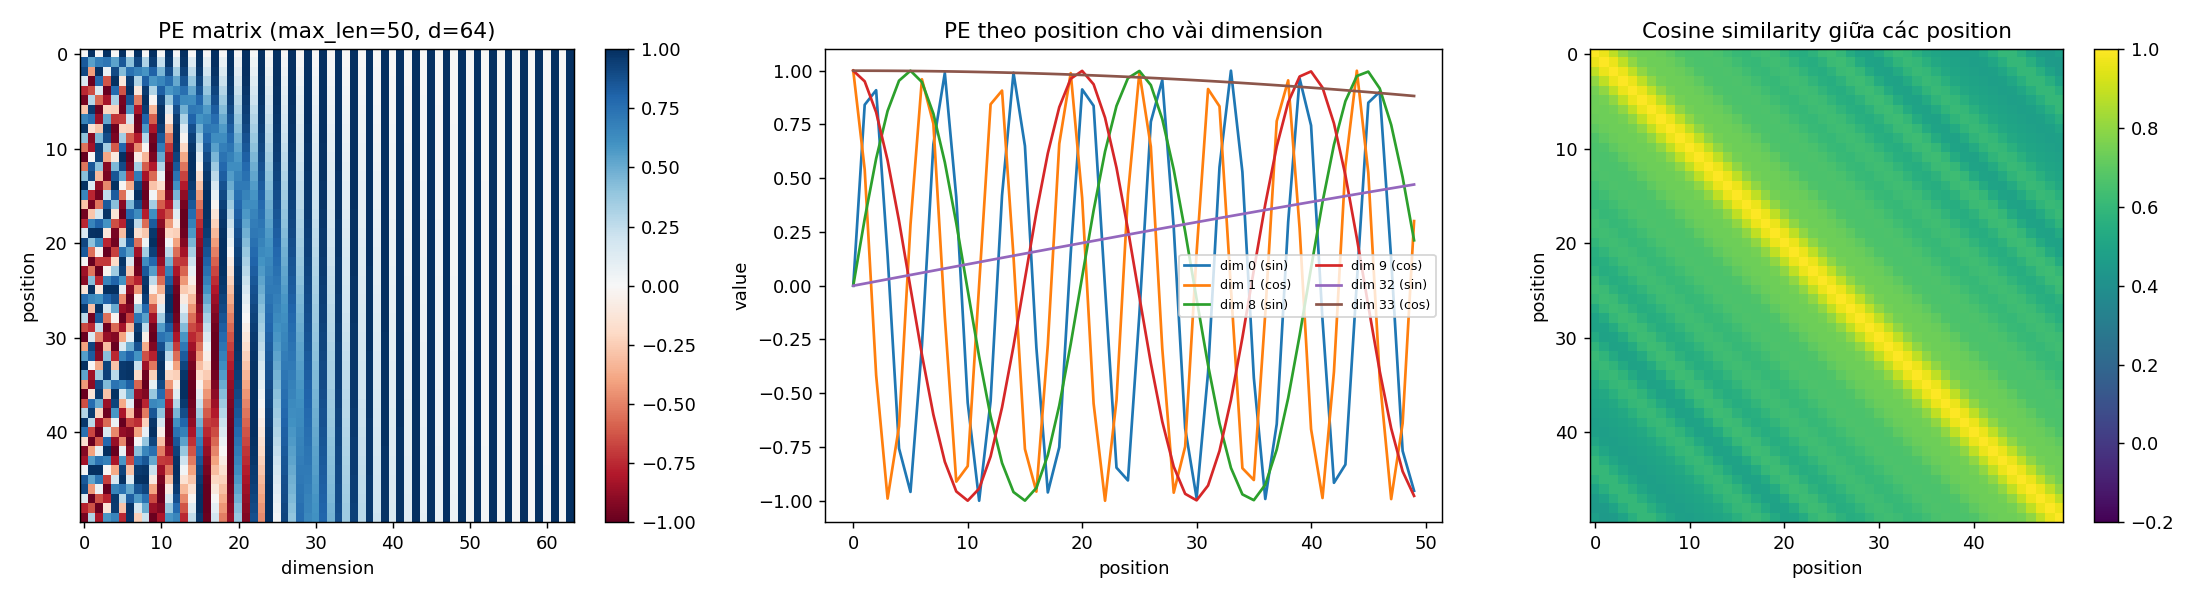

In [4]:
np.set_printoptions(precision=4, suppress=True)
print("PE (d=4), pos = 0, 1, 2:\n", pe_mod.sinusoidal_pe(3, 4))
pe_mod.plot_positional_encoding("positional_encoding.png")
from IPython.display import Image, display
display(Image("positional_encoding.png"))

In [5]:
# Experiment 1: ["I","love","NLP"] -> ["NLP","love","I"]; Experiment permutation: dog bites man / man bites dog
rows = []
for t1, t2 in ((["I", "love", "NLP"], ["NLP", "love", "I"]), (["dog", "bites", "man"], ["man", "bites", "dog"])):
    for layer_name, use_block in (("Multi-head self-attention", False), ("Full TransformerBlock", True)):
        res = pe_mod.permutation_experiment(t1, t2, use_block=use_block)
        for exp, r in res.items():
            rows.append({"S1": " ".join(t1), "S2": " ".join(t2), "layer": layer_name, "experiment": exp,
                         "cosine(pooled S1, pooled S2)": r["pooled_cosine"], "max|diff| pooled": r["pooled_max_abs_diff"],
                         "max over words of max|diff| (cùng từ, 2 câu)": max(r["per_word_max_abs_diff"].values())})
perm = pd.DataFrame(rows); perm.to_csv("permutation_results.csv", index=False)
perm.style.format({"cosine(pooled S1, pooled S2)": "{:.6f}", "max|diff| pooled": "{:.2e}", "max over words of max|diff| (cùng từ, 2 câu)": "{:.2e}"})

,S1,S2,layer,experiment,"cosine(pooled S1, pooled S2)",max|diff| pooled,"max over words of max|diff| (cùng từ, 2 câu)"
0,I love NLP,NLP love I,Multi-head self-attention,A (no PE),1.000000,2.98e-08,5.96e-08
1,I love NLP,NLP love I,Multi-head self-attention,B (with PE),0.999396,1.65e-02,5.67e-02
2,I love NLP,NLP love I,Full TransformerBlock,A (no PE),1.000000,2.38e-07,3.58e-07
3,I love NLP,NLP love I,Full TransformerBlock,B (with PE),0.998435,1.16e-01,1.31e+00
4,dog bites man,man bites dog,Multi-head self-attention,A (no PE),1.000000,2.98e-08,5.96e-08
5,dog bites man,man bites dog,Multi-head self-attention,B (with PE),0.999345,3.14e-02,4.82e-02
6,dog bites man,man bites dog,Full TransformerBlock,A (no PE),1.000000,1.19e-07,1.19e-07
7,dog bites man,man bites dog,Full TransformerBlock,B (with PE),0.999195,1.16e-01,1.31e+00


In [6]:
# Chi tiết: biểu diễn từng token "dog" trong S1 (vị trí 0) và S2 (vị trí 2), Transformer block đầy đủ
res = pe_mod.permutation_experiment(["dog", "bites", "man"], ["man", "bites", "dog"], use_block=True)
for exp, r in res.items():
    print(exp, "| 'dog' trong S1 [:4] =", r["out_1"][0, :4].round(4), "| 'dog' trong S2 [:4] =", r["out_2"][2, :4].round(4))

A (no PE) | 'dog' trong S1 [:4] = [-1.4118 -1.4529  0.4021  0.9041] | 'dog' trong S2 [:4] = [-1.4118 -1.4529  0.4021  0.9041]
B (with PE) | 'dog' trong S1 [:4] = [-1.7525 -1.0892 -0.0601  0.8795] | 'dog' trong S2 [:4] = [-0.9186 -2.0554  0.3377  0.6504]


## 2. Dữ liệu IMDb (split / tokenizer giống LAB 04–06)

In [7]:
raw_train, raw_test = pp.load_imdb()
for df in (raw_train, raw_test):
    df["tokens"] = df["text"].map(pp.tokenize); df["n_tokens"] = df["tokens"].map(len); df["norm"] = df["text"].map(pp.clean_text)
overlap = set(raw_train["norm"]) & set(raw_test["norm"])
conflict = raw_train.groupby("norm")["label"].transform("nunique") > 1
clean = (raw_train[~conflict].drop_duplicates("norm").loc[lambda d: ~d["norm"].isin(overlap)].reset_index(drop=True))
train_df, val_df = pp.split_train_val(clean, val_size=0.2)
test_df = raw_test.reset_index(drop=True)
y_train, y_val, y_test = (d["label"].to_numpy() for d in (train_df, val_df, test_df))
vocab = pp.Vocabulary(train_df["tokens"], max_size=20_000, min_freq=2); V_SIZE = len(vocab)
MAX_LEN = 200
_enc = {}
def get_data(L):
    if L not in _enc:
        _enc[L] = {n: pp.encode_corpus(d["tokens"], vocab, L, "head") for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]}
    return _enc[L]
print(f"train {len(train_df):,} | val {len(val_df):,} | test {len(test_df):,} | vocab {V_SIZE:,} | max_len {MAX_LEN}")
print("median / mean #tokens (train):", train_df["n_tokens"].median(), round(train_df["n_tokens"].mean(), 1))

def run(key, factory, L=MAX_LEN, seed=tm.SEED, name=None):
    path = f"{CACHE}/{key}.pt"
    if os.path.exists(path):
        r = torch.load(path, weights_only=False); r["model"] = r["model"].to(tm.DEVICE); return r
    print(f"== {key} ==", flush=True)
    r = tm.train_model(name or key, factory(), get_data(L), y_train, y_val, y_test, L, seed=seed)
    torch.save({**r, "model": r["model"].cpu()}, path); r["model"] = r["model"].to(tm.DEVICE)
    return r

def min_epoch(r):
    # GPU/CPU được dùng chung với tiến trình khác nên thời gian mỗi epoch nhiễu; min epoch time là ước lượng ít nhiễu nhất
    return r["history"]["epoch_time_s"].min()

TF = lambda **kw: (lambda: tm.TransformerClassifier(V_SIZE, **kw))

train 19,823 | val 4,956 | test 25,000 | vocab 20,002 | max_len 200
median / mean #tokens (train): 174.0 233.2


## 3. Experiment 4 — Transformer vs LSTM (cùng split, vocab, emb dim 128, batch 64, Adam 1e-3, 8 epochs, seed 42)
Model A: Embedding → LSTM → Classifier. Model B: Embedding → Positional Encoding → Transformer Encoder (1 block, 4 heads, d_ff=256) → mean pooling → Classifier.

In [8]:
RUNS = {}
RUNS["LSTM"] = run("lstm", lambda: tm.LSTMClassifier(V_SIZE), name="LSTM")
RUNS["Transformer"] = run("tf_h4_mean", TF(), name="Transformer (4 heads, mean)")
cmp = pd.DataFrame([{**r["row"], "min_epoch_s": min_epoch(r)} for r in RUNS.values()])
cmp[["model", "n_params", "train_time_s", "min_epoch_s", "accuracy", "precision", "recall", "f1", "best_epoch"]].round(4)

,model,n_params,train_time_s,min_epoch_s,accuracy,precision,recall,f1,best_epoch
0,LSTM,2692481,301.0086,17.8068,0.8090,0.7844,0.8524,0.8170,6
1,"Transformer (4 heads, mean)",2692865,238.7963,26.8931,0.8394,0.8289,0.8554,0.8419,3


In [9]:
# Learning curves (train/val loss theo epoch) + confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (k, r) in zip(axes, RUNS.items()):
    h = r["history"]
    ax.plot(h["epoch"], h["train_loss"], "o--", label="train loss"); ax.plot(h["epoch"], h["val_loss"], "s-", label="val loss")
    ax.axvline(r["row"]["best_epoch"], ls=":", c="gray", label=f"best epoch = {r['row']['best_epoch']}")
    ax.set(title=k, xlabel="epoch", ylabel="BCE loss"); ax.legend()
plt.tight_layout(); plt.savefig("learning_curves.png", dpi=150); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (k, r) in zip(axes, RUNS.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, r["y_pred"]), display_labels=["negative", "positive"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{k} (acc {r['row']['accuracy']:.4f})")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=150); plt.show()
for k, r in RUNS.items(): print(k, "\n", r["history"].round(4).to_string(index=False))

LSTM 
  epoch  train_loss  val_loss  val_acc  val_f1  epoch_time_s
     1      0.6441    0.5698   0.7236  0.6868       17.8068
     2      0.5425    0.5685   0.7088  0.6520       25.2209
     3      0.4696    0.5904   0.7034  0.7643       25.4961
     4      0.3967    0.4794   0.8061  0.8199       44.9772
     5      0.3302    0.4576   0.8073  0.8242       46.7569
     6      0.2673    0.4137   0.8251  0.8329       46.7037
     7      0.2119    0.4708   0.8370  0.8447       46.8397
     8      0.1624    0.5242   0.8438  0.8483       47.2074
Transformer 
  epoch  train_loss  val_loss  val_acc  val_f1  epoch_time_s
     1      0.5529    0.4375   0.7954  0.8156       26.8931
     2      0.3737    0.3589   0.8410  0.8467       28.9055
     3      0.2881    0.3380   0.8525  0.8573       28.7687
     4      0.2219    0.3613   0.8515  0.8490       28.8680
     5      0.1601    0.4334   0.8396  0.8290       29.0261
     6      0.1129    0.4601   0.8511  0.8481       28.0247
     7      0.0714 

In [10]:
# Thêm 2 seed (43, 44) cho LSTM và Transformer để biết mức dao động giữa các lần chạy
SEED_ROWS = [{**RUNS[k]["row"], "seed": tm.SEED, "model": k} for k in RUNS]
for s in (43, 44):
    SEED_ROWS.append({**run(f"lstm_s{s}", lambda: tm.LSTMClassifier(V_SIZE), seed=s, name="LSTM")["row"], "seed": s, "model": "LSTM"})
    SEED_ROWS.append({**run(f"tf_h4_mean_s{s}", TF(), seed=s, name="Transformer")["row"], "seed": s, "model": "Transformer"})
seeds = pd.DataFrame(SEED_ROWS)
display(seeds[["model", "seed", "accuracy", "f1", "train_time_s", "best_epoch"]].round(4))
seeds.groupby("model")[["accuracy", "f1", "train_time_s"]].agg(["mean", "std"]).round(4)

,model,seed,accuracy,f1,train_time_s,best_epoch
0,LSTM,42,0.8090,0.8170,301.0086,6
1,Transformer,42,0.8394,0.8419,238.7963,3
2,LSTM,43,0.8155,0.8160,370.8642,5
3,Transformer,43,0.8341,0.8274,189.8386,3
4,LSTM,44,0.8143,0.8073,306.2255,8
5,Transformer,44,0.8441,0.8469,191.3391,3


accuracy              f1         train_time_s         
                mean     std    mean     std         mean      std
model                                                             
LSTM          0.8129  0.0034  0.8134  0.0053     326.0328  38.9127
Transformer   0.8392  0.0050  0.8388  0.0101     206.6580  27.8427

## 4. Experiment 2 — Số attention heads (`d_model = 128` cố định)
`d_k = d_model / n_heads`. Số tham số gần như không đổi vì `W_Q, W_K, W_V, W_O` luôn là `d_model × d_model`.

In [11]:
HEAD_RUNS = {4: RUNS["Transformer"]}
for h in (1, 2, 8):
    HEAD_RUNS[h] = run(f"tf_h{h}_mean", TF(n_heads=h), name=f"Transformer ({h} heads)")
heads_df = pd.DataFrame([{"Heads": h, "d_k": 128 // h, "Parameters": r["row"]["n_params"], "Training time (s)": r["row"]["train_time_s"], "Min epoch time (s)": min_epoch(r),
                          "Accuracy": r["row"]["accuracy"], "F1": r["row"]["f1"], "best_epoch": r["row"]["best_epoch"]}
                         for h, r in sorted(HEAD_RUNS.items())])
heads_df.round(4)

,Heads,d_k,Parameters,Training time (s),Min epoch time (s),Accuracy,F1,best_epoch
0,1,128,2692865,148.6124,17.6029,0.8433,0.8436,3
1,2,64,2692865,165.7234,17.6828,0.8360,0.8421,3
2,4,32,2692865,238.7963,26.8931,0.8394,0.8419,3
3,8,16,2692865,272.3468,24.9559,0.8398,0.8406,3


## 5. Experiment 3 — Attention head diversity (model 4 heads, 1 block)

In [12]:
model = RUNS["Transformer"]["model"].eval()
def encode_text(text, L=MAX_LEN):
    toks = pp.tokenize(text)[:L]
    ids = torch.tensor([vocab.encode(toks) or [pp.UNK]], device=tm.DEVICE)
    return toks, ids, torch.tensor([ids.size(1)])

@torch.no_grad()
def attend(text, mdl=None):
    mdl = mdl or model
    toks, ids, ln = encode_text(text)
    logit, attns = mdl(ids, ln, return_attention=True)
    return toks, torch.sigmoid(logit).item(), attns[0][0].cpu().numpy()      # A: [h, T, T]

SENT = "I did not like this movie because the acting was terrible but the music was great."
toks, p, A = attend(SENT)
print(f"{SENT!r}\nP(pos) = {p:.3f}; A shape = {A.shape}")
flat = A.reshape(4, -1); flat = flat / np.linalg.norm(flat, axis=1, keepdims=True)
print("cosine giữa các head trên câu này:\n", np.round(flat @ flat.T, 3))
for h in range(4): print(f"head {h+1}: token nhận nhiều attention nhất (TB theo query) =", [toks[j] for j in np.argsort(-A[h].mean(0))[:3]])

@torch.no_grad()
def head_stats(mdl, n=500, L=100, seed=0):
    # thống kê trên n review test (cắt ở L token): entropy chuẩn hóa, khoảng cách attention, attention lên chính nó, tương đồng giữa head
    rng = np.random.default_rng(seed); idx = rng.choice(len(test_df), n, replace=False)
    ent, dist, selfw, sim = [], [], [], []
    mdl.eval()
    for i in idx:
        toks_i = test_df["tokens"].iloc[i][:L]
        if len(toks_i) < 10: continue
        ids = torch.tensor([vocab.encode(toks_i)], device=tm.DEVICE)
        _, attns = mdl(ids, torch.tensor([len(toks_i)]), return_attention=True)
        Ai = attns[0][0].cpu().numpy()                       # [h, T, T]
        T = Ai.shape[-1]; H = Ai.shape[0]
        e = -(Ai * np.log(Ai + 1e-12)).sum(-1) / np.log(T)  # [h, T] entropy / ln T  (1 = uniform)
        ent.append(e.mean(1))
        ii, jj = np.indices((T, T)); dist.append((Ai * np.abs(ii - jj)).sum((1, 2)) / T)
        selfw.append(np.diagonal(Ai, axis1=1, axis2=2).mean(1))
        flat = Ai.reshape(H, -1); flat = flat / np.linalg.norm(flat, axis=1, keepdims=True); sim.append(flat @ flat.T)
    return {"entropy": np.mean(ent, 0), "distance": np.mean(dist, 0), "self": np.mean(selfw, 0), "sim": np.mean(sim, 0)}

st_trained = head_stats(model)
tm.set_seed(); untrained = tm.TransformerClassifier(V_SIZE).to(tm.DEVICE)      # khởi tạo ngẫu nhiên, chưa train (baseline)
st_init = head_stats(untrained)
rows = [{"head": h + 1, "entropy/ln T (trained)": st_trained["entropy"][h], "mean |i-j| (trained)": st_trained["distance"][h],
         "attn on self (trained)": st_trained["self"][h], "entropy/ln T (init)": st_init["entropy"][h]} for h in range(4)]
display(pd.DataFrame(rows).round(3))
off = lambda s: s[np.triu_indices(4, 1)]
print("cosine giữa các cặp head (trained): mean = %.3f, min = %.3f, max = %.3f" % (off(st_trained["sim"]).mean(), off(st_trained["sim"]).min(), off(st_trained["sim"]).max()))
print("cosine giữa các cặp head (init)   : mean = %.3f" % off(st_init["sim"]).mean())
print(np.round(st_trained["sim"], 3))

'I did not like this movie because the acting was terrible but the music was great.'
P(pos) = 0.008; A shape = (4, 16, 16)
cosine giữa các head trên câu này:
 [[1.    0.425 0.532 0.273]
 [0.425 1.    0.192 0.305]
 [0.532 0.192 1.    0.103]
 [0.273 0.305 0.103 1.   ]]
head 1: token nhận nhiều attention nhất (TB theo query) = ['terrible', 'not', 'did']
head 2: token nhận nhiều attention nhất (TB theo query) = ['not', 'but', 'movie']
head 3: token nhận nhiều attention nhất (TB theo query) = ['terrible', 'great', 'movie']
head 4: token nhận nhiều attention nhất (TB theo query) = ['acting', 'i', 'did']


,head,entropy/ln T (trained),mean |i-j| (trained),attn on self (trained),entropy/ln T (init)
0,1,0.804,32.655,0.012,0.979
1,2,0.694,32.620,0.019,0.979
2,3,0.679,33.416,0.012,0.978
3,4,0.696,34.298,0.013,0.976


cosine giữa các cặp head (trained): mean = 0.141, min = 0.089, max = 0.174
cosine giữa các cặp head (init)   : mean = 0.819
[[1.    0.167 0.172 0.174]
 [0.167 1.    0.089 0.105]
 [0.172 0.089 1.    0.137]
 [0.174 0.105 0.137 1.   ]]


In [13]:
fig = plt.figure(figsize=(18, 9.5)); gs = fig.add_gridspec(2, 4, height_ratios=[2.2, 1])
for h in range(4):
    ax = fig.add_subplot(gs[0, h]); im = ax.imshow(A[h], cmap="viridis", vmin=0)
    ax.set_xticks(range(len(toks)), toks, rotation=70, ha="right", fontsize=8); ax.set_yticks(range(len(toks)), toks, fontsize=8)
    ax.set_title(f"Head {h+1}"); ax.set_xlabel("key (attend tới)")
    if h == 0: ax.set_ylabel("query")
    plt.colorbar(im, ax=ax, fraction=0.046)
ax = fig.add_subplot(gs[1, 0]); w = 0.38; x = np.arange(4)
ax.bar(x - w/2, st_trained["entropy"], w, label="trained"); ax.bar(x + w/2, st_init["entropy"], w, label="init (chưa train)")
ax.set_xticks(x, [f"H{i+1}" for i in x]); ax.set_ylabel("entropy / ln T"); ax.set_title("Độ phân tán (1 = uniform)"); ax.legend(fontsize=8)
ax = fig.add_subplot(gs[1, 1]); ax.bar(x, st_trained["distance"]); ax.set_xticks(x, [f"H{i+1}" for i in x]); ax.set_title("Khoảng cách attention trung bình |i-j|")
ax = fig.add_subplot(gs[1, 2]); im = ax.imshow(st_trained["sim"], vmin=0, vmax=1, cmap="magma"); ax.set_xticks(x, [f"H{i+1}" for i in x]); ax.set_yticks(x, [f"H{i+1}" for i in x])
for i in range(4):
    for j in range(4): ax.text(j, i, f"{st_trained['sim'][i, j]:.2f}", ha="center", va="center", color="w", fontsize=8)
ax.set_title("Cosine giữa attention matrix các head"); plt.colorbar(im, ax=ax, fraction=0.046)
ax = fig.add_subplot(gs[1, 3]); ax.bar(x, st_trained["self"]); ax.set_xticks(x, [f"H{i+1}" for i in x]); ax.set_title("Attention lên chính token đó")
plt.tight_layout(); plt.savefig("attention_heads.png", dpi=140); plt.show()

## 6. Experiment 5 — Sequence length (`max_length` = 32, 64, 128, 256; Transformer 4 heads, mean pooling)
Attention memory = tensor attention weights `[B=64, h=4, T, T]` float32 (lý thuyết, 1 block).

In [14]:
LEN_RUNS = {}
for L in (32, 64, 128, 256):
    LEN_RUNS[L] = run(f"tf_len{L}", TF(), L=L, name=f"Transformer (len {L})")
full = train_df["n_tokens"].to_numpy()
len_df = pd.DataFrame([{"Length": L, "Tokens retained (%)": pp.pct_tokens_retained(full, L), "Attention matrix": f"{L}x{L} = {L*L:,}",
                        "Attention memory (MB)": tm.attention_memory_mb(L, 4), "Training time (s)": r["row"]["train_time_s"], "Min epoch time (s)": min_epoch(r),
                        "Accuracy": r["row"]["accuracy"], "F1": r["row"]["f1"]} for L, r in LEN_RUNS.items()])
len_df.round(4)

,Length,Tokens retained (%),Attention matrix,Attention memory (MB),Training time (s),Min epoch time (s),Accuracy,F1
0,32,13.7135,"32x32 = 1,024",1.0,85.7431,5.6776,0.7038,0.6968
1,64,27.1437,"64x64 = 4,096",4.0,161.4043,14.4909,0.7616,0.7641
2,128,51.2426,"128x128 = 16,384",16.0,176.6836,18.0480,0.8122,0.8106
3,256,76.7412,"256x256 = 65,536",64.0,274.1509,22.5840,0.8508,0.8537


In [15]:
# LƯU Ý: GPU/CPU dùng chung với các tiến trình khác khi chạy => cột thời gian NHIỄU; peak memory thì xác định.
# Micro-benchmark thời gian + peak GPU memory forward+backward (1 block 4 heads vs LSTM), batch 16, synthetic input, T tăng dần (min của 7 lần đo).
def bench(model, T, dev, B=16, reps=7):
    model = model.to(dev); ids = torch.randint(2, 1000, (B, T), device=dev); ln = torch.full((B,), T)
    opt = torch.optim.SGD(model.parameters(), lr=1e-3)
    def step():
        opt.zero_grad(); model(ids, ln).sum().backward(); opt.step()
    step(); step()
    mem = np.nan
    if dev.type == "cuda":
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats(); base = torch.cuda.memory_allocated()
    ts = []
    for _ in range(reps):
        if dev.type == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter(); step()
        if dev.type == "cuda": torch.cuda.synchronize()
        ts.append(time.perf_counter() - t0)
    if dev.type == "cuda": mem = (torch.cuda.max_memory_allocated() - base) / 2**20      # peak MB của activations (xác định, không nhiễu)
    return min(ts) * 1000, mem      # min over reps: ít nhiễu hơn khi máy đang chạy tiến trình khác

rows = []
devs = [torch.device("cpu")] + ([tm.DEVICE] if tm.DEVICE.type == "cuda" else [])
for dev in devs:
    for T in (32, 64, 128, 256, 512, 1024, 2048):
        if dev.type == "cpu" and T > 1024: continue
        torch.manual_seed(0)
        (l_ms, l_mem), (t_ms, t_mem) = bench(tm.LSTMClassifier(1000), T, dev), bench(tm.TransformerClassifier(1000, max_len=2100), T, dev)
        rows.append({"device": dev.type, "T": T, "LSTM (ms)": l_ms, "Transformer (ms)": t_ms, "LSTM peak MB": l_mem, "Transformer peak MB": t_mem})
bench_df = pd.DataFrame(rows); bench_df["Transformer/LSTM (time)"] = bench_df["Transformer (ms)"] / bench_df["LSTM (ms)"]
bench_df.round(2)

,device,T,LSTM (ms),Transformer (ms),LSTM peak MB,Transformer peak MB,Transformer/LSTM (time)
0,cpu,32,71.54,39.65,NaN,NaN,0.55
1,cpu,64,123.25,84.59,NaN,NaN,0.69
2,cpu,128,423.85,170.37,NaN,NaN,0.40
3,cpu,256,2125.88,328.43,NaN,NaN,0.15
4,cpu,512,2308.59,801.39,NaN,NaN,0.35
5,cpu,1024,1270.60,2236.69,NaN,NaN,1.76
6,cuda,32,114.95,42.35,12.22,3.64,0.37
7,cuda,64,172.97,29.95,14.61,10.27,0.17
8,cuda,128,300.86,39.75,21.11,26.01,0.13
9,cuda,256,481.14,89.16,34.32,73.33,0.19


In [16]:
fig, ax = plt.subplots(1, 4, figsize=(21, 4))
ax[0].plot(len_df["Length"], len_df["F1"], "o-"); ax[0].set(xlabel="max_length", ylabel="test F1", title="F1 theo max_length", xscale="log", xticks=[32, 64, 128, 256], xticklabels=[32, 64, 128, 256])
ax[1].plot(len_df["Length"], len_df["Training time (s)"], "o-", label="train time (s)"); ax[1].set(xlabel="max_length", title="Train time và attention memory", xscale="log")
a2 = ax[1].twinx(); a2.plot(len_df["Length"], len_df["Attention memory (MB)"], "s--", c="C3", label="attention memory (MB)"); a2.set_ylabel("MB", color="C3")
for dev, g in bench_df.groupby("device"):
    ax[2].plot(g["T"], g["LSTM (ms)"], "o--", label=f"LSTM ({dev})"); ax[2].plot(g["T"], g["Transformer (ms)"], "s-", label=f"Transformer ({dev})")
ax[2].set(xscale="log", yscale="log", xlabel="T", ylabel="ms / step (B=16)", title="forward+backward theo T (thời gian nhiễu)"); ax[2].legend(fontsize=8)
g = bench_df[bench_df["device"] == "cuda"]
if len(g):
    ax[3].plot(g["T"], g["LSTM peak MB"], "o--", label="LSTM"); ax[3].plot(g["T"], g["Transformer peak MB"], "s-", label="Transformer")
    ax[3].plot(g["T"], g["Transformer peak MB"].iloc[0] * (g["T"] / g["T"].iloc[0]) ** 2, ":", c="gray", label="∝ T²")
    ax[3].set(xscale="log", yscale="log", xlabel="T", ylabel="peak GPU MB (B=16)", title="Peak memory forward+backward"); ax[3].legend(fontsize=8)
plt.tight_layout(); plt.savefig("sequence_length.png", dpi=140); plt.show()

## 7. Experiment 6 — Pooling (Mean vs CLS-style) và ablation positional encoding trên IMDb

In [17]:
POOL_RUNS = {"Mean": RUNS["Transformer"], "CLS-style": run("tf_h4_cls", TF(pooling="cls"), name="Transformer (CLS pooling)")}
pool_df = pd.DataFrame([{"Pooling": k, "Accuracy": r["row"]["accuracy"], "F1": r["row"]["f1"], "Training time (s)": r["row"]["train_time_s"], "Min epoch time (s)": min_epoch(r), "best_epoch": r["row"]["best_epoch"]} for k, r in POOL_RUNS.items()])
display(pool_df.round(4))
NOPE = run("tf_h4_mean_nope", TF(use_pe=False), name="Transformer (no PE)")
pe_df = pd.DataFrame([{"Variant": k, "Accuracy": r["row"]["accuracy"], "F1": r["row"]["f1"], "best_epoch": r["row"]["best_epoch"]}
                      for k, r in {"with PE": RUNS["Transformer"], "no PE": NOPE}.items()])
pe_df.round(4)

,Pooling,Accuracy,F1,Training time (s),Min epoch time (s),best_epoch
0,Mean,0.8394,0.8419,238.7963,26.8931,3
1,CLS-style,0.8364,0.8380,641.3148,62.9777,3


,Variant,Accuracy,F1,best_epoch
0,with PE,0.8394,0.8419,3
1,no PE,0.8406,0.8402,2


## 8. Application — dự đoán sentiment (câu ngắn, dài, negation, contrast, ambiguous)

In [18]:
tests = {
 "short": "I really enjoyed this movie.",
 "short (neg)": "This was a terrible film.",
 "long": ("I went into this film with low expectations because the trailer looked generic, but within the first twenty minutes I was completely absorbed. "
          "The cast is superb, the script is sharp and funny, the cinematography is beautiful and the ending genuinely moved me. I would happily watch it again."),
 "negation": "I did not like this movie at all.",
 "negation (positive)": "This movie is not bad.",
 "contrast": "I thought this movie would be bad, but it was actually excellent.",
 "contrast 2": "The acting was great, but the story was boring and far too long.",
 "ambiguous": "The movie was okay, I guess. Some parts were fine and some were not.",
}
def predict(mdl, text):
    toks, ids, ln = encode_text(text)
    with torch.no_grad(): p = torch.sigmoid(mdl(ids, ln)).item()
    return p
rows = []
for k, s in tests.items():
    rows.append({"type": k, "text": s[:70] + ("..." if len(s) > 70 else ""), "Transformer P(pos)": predict(RUNS["Transformer"]["model"].eval(), s),
                 "Transformer (no PE) P(pos)": predict(NOPE["model"].eval(), s), "LSTM P(pos)": predict(RUNS["LSTM"]["model"].eval(), s)})
app = pd.DataFrame(rows)
for c in ("Transformer", "Transformer (no PE)", "LSTM"): app[c + " pred"] = np.where(app[c + " P(pos)"] >= 0.5, "positive", "negative")
app.round(3)

,type,text,Transformer P(pos),Transformer (no PE) P(pos),LSTM P(pos),Transformer pred,Transformer (no PE) pred,LSTM pred
0,short,I really enjoyed this movie.,0.997,0.998,0.850,positive,positive,positive
1,short (neg),This was a terrible film.,0.001,0.002,0.032,negative,negative,negative
2,long,I went into this film with low expectations be...,0.947,0.889,0.824,positive,positive,positive
3,negation,I did not like this movie at all.,0.007,0.041,0.384,negative,negative,negative
4,negation (positive),This movie is not bad.,0.001,0.002,0.163,negative,negative,negative
5,contrast,"I thought this movie would be bad, but it was ...",0.630,0.763,0.839,positive,positive,positive
6,contrast 2,"The acting was great, but the story was boring...",0.087,0.297,0.020,negative,negative,negative
7,ambiguous,"The movie was okay, I guess. Some parts were f...",0.308,0.228,0.201,negative,negative,negative


In [19]:
# Hoán vị từ trên IMDb: model có / không có PE phản ứng thế nào với câu bị xáo trộn thứ tự?
s = "this movie was not good it was actually quite bad"
shuf = " ".join(np.random.default_rng(0).permutation(s.split()))
for name, mdl in (("Transformer", RUNS["Transformer"]["model"]), ("Transformer (no PE)", NOPE["model"])):
    print(f"{name:<22s} original: {predict(mdl.eval(), s):.4f} | shuffled ({shuf!r}): {predict(mdl.eval(), shuf):.4f}")
# Với no-PE hai xác suất phải giống hệt nhau (permutation invariance của mean pooling + self-attention)

Transformer            original: 0.0334 | shuffled ('good was was actually not it bad this quite movie'): 0.0345
Transformer (no PE)    original: 0.0988 | shuffled ('good was was actually not it bad this quite movie'): 0.0988


## 9. Error analysis — 3 mẫu đúng + 3 mẫu sai của Transformer (kèm token nhận nhiều attention nhất)

In [20]:
r = RUNS["Transformer"]; proba, pred = r["proba"], r["y_pred"]
rng = np.random.default_rng(42)
correct = rng.choice(np.where(pred == y_test)[0], 3, replace=False); wrong = rng.choice(np.where(pred != y_test)[0], 3, replace=False)

@torch.no_grad()
def top_attended(i, k=5):
    toks_i = test_df["tokens"].iloc[i][:MAX_LEN]
    ids = torch.tensor([vocab.encode(toks_i)], device=tm.DEVICE)
    _, attns = model(ids, torch.tensor([len(toks_i)]), return_attention=True)
    recv = attns[0][0].mean(0).mean(0).cpu().numpy()        # attention nhận được của mỗi token: TB theo head và theo query
    idx = np.argsort(-recv)[:k]
    return ", ".join(f"{toks_i[j]}({recv[j]:.3f})" for j in idx), 1 / len(toks_i)

rows = []
for tag, idxs in (("đúng", correct), ("sai", wrong)):
    for i in idxs:
        top, uni = top_attended(i)
        rows.append({"idx": int(i), "nhóm": tag, "true": pp.LABEL_NAMES[y_test[i]], "pred": pp.LABEL_NAMES[pred[i]], "P(pos)": round(float(proba[i]), 3),
                     "n_tokens": int(test_df["n_tokens"].iloc[i]), "uniform 1/T": round(uni, 4), "top-5 attended": top,
                     "text (300 ký tự đầu)": test_df["text"].iloc[i][:300].replace("<br />", " ")})
errs = pd.DataFrame(rows); errs.to_csv("error_samples.csv", index=False)
for _, row in errs.iterrows():
    print(f"[{row['idx']}] {row['nhóm']} | true={row['true']} pred={row['pred']} P={row['P(pos)']} | n_tokens={row['n_tokens']} (1/T={row['uniform 1/T']})\n   top-5: {row['top-5 attended']}\n   {row['text (300 ký tự đầu)']}\n")

[16510] đúng | true=positive pred=positive P=0.849 | n_tokens=308 (1/T=0.005)
   top-5: builds(0.064), town(0.038), nose(0.023), town(0.023), attempt(0.020)
   As with so many modern US films, there has to be a supernatural element to the plot, but if you just let that go, this is a tale with heaps of charm and a kindly heart cased in a crab shell.  We are presented with a scene of a town in an economically depressed area struggling to find anyth

[2285] đúng | true=negative pred=negative P=0.206 | n_tokens=632 (1/T=0.005)
   top-5: nothing(0.046), cut(0.046), stupid(0.036), remember(0.031), mediocre(0.018)
   The Net is a movie I never saw upon release, I remember giving it a pass upon the mediocre reviews and since then perhaps been noticing a snippet here and there when it's been on TV. Seeing it now, fourteen years after it's original release, I'm a little flabbergasted as to how time flies. Being in 

[19447] đúng | true=positive pred=positive P=0.711 | n_tokens=573 (1/T=0.005)
  

## 10. Tổng hợp — `results.csv`

In [21]:
allrows = []
def add(exp, rr, **extra):
    allrows.append({"experiment": exp, **rr["row"], "min_epoch_s": min_epoch(rr), **extra})
add("Exp4 LSTM vs Transformer", RUNS["LSTM"]); add("Exp4 LSTM vs Transformer", RUNS["Transformer"])
for h, rr in sorted(HEAD_RUNS.items()): add("Exp2 heads", rr, n_heads=h, d_k=128 // h)
for L, rr in LEN_RUNS.items(): add("Exp5 seq length", rr, tokens_retained_pct=pp.pct_tokens_retained(full, L), attn_mem_mb=tm.attention_memory_mb(L, 4))
add("Exp6 pooling", POOL_RUNS["CLS-style"]); add("Ablation PE", NOPE)
res_all = pd.DataFrame(allrows); res_all.to_csv("results.csv", index=False)
seeds.to_csv("results_seeds.csv", index=False); bench_df.to_csv("benchmark_forward_backward.csv", index=False)
res_all[["experiment", "model", "max_len", "n_params", "train_time_s", "min_epoch_s", "accuracy", "precision", "recall", "f1", "best_epoch"]].round(4)

,experiment,model,max_len,n_params,train_time_s,min_epoch_s,accuracy,precision,recall,f1,best_epoch
0,Exp4 LSTM vs Transformer,LSTM,200,2692481,301.0086,17.8068,0.8090,0.7844,0.8524,0.8170,6
1,Exp4 LSTM vs Transformer,"Transformer (4 heads, mean)",200,2692865,238.7963,26.8931,0.8394,0.8289,0.8554,0.8419,3
2,Exp2 heads,Transformer (1 heads),200,2692865,148.6124,17.6029,0.8433,0.8423,0.8448,0.8436,3
3,Exp2 heads,Transformer (2 heads),200,2692865,165.7234,17.6828,0.8360,0.8117,0.8750,0.8421,3
4,Exp2 heads,"Transformer (4 heads, mean)",200,2692865,238.7963,26.8931,0.8394,0.8289,0.8554,0.8419,3
5,Exp2 heads,Transformer (8 heads),200,2692865,272.3468,24.9559,0.8398,0.8363,0.8450,0.8406,3
6,Exp5 seq length,Transformer (len 32),32,2692865,85.7431,5.6776,0.7038,0.7135,0.6809,0.6968,4
7,Exp5 seq length,Transformer (len 64),64,2692865,161.4043,14.4909,0.7616,0.7563,0.7721,0.7641,3
8,Exp5 seq length,Transformer (len 128),128,2692865,176.6836,18.0480,0.8122,0.8175,0.8037,0.8106,3
9,Exp5 seq length,Transformer (len 256),256,2692865,274.1509,22.5840,0.8508,0.8375,0.8706,0.8537,3


## Nhận xét tổng hợp
Phân tích chi tiết nằm ở `calculations.md`, `prediction.md` (kèm bảng kiểm chứng), `error_analysis.md`, `reflection.md`. Tóm tắt kết quả:
- **Core:** `TransformerBlock` tự ghép khớp `nn.TransformerEncoderLayer` (sai lệch 3.6e-07), shape đúng `B×h×T×d_k`, scores `B×h×T×T`.
- **PE / permutation:** không PE ⇒ hai câu hoán vị cho biểu diễn giống hệt (cosine 1.000000, sai lệch ~1e-8); có PE ⇒ khác nhau. Nhưng trên IMDb, PE không cải thiện accuracy (0.8394 vs 0.8406).
- **Heads:** số tham số không đổi khi tăng heads (d_model cố định); accuracy 0.836–0.843, trong nhiễu giữa seed. Các head khác nhau (cosine 0.14 sau train vs 0.82 lúc khởi tạo).
- **Transformer vs LSTM (3 seed):** accuracy 0.8392±0.0050 vs 0.8129±0.0034; Transformer overfit sớm (best epoch 3).
- **Sequence length:** F1 0.697 / 0.764 / 0.811 / 0.854 cho T = 32 / 64 / 128 / 256; attention memory tăng 4× mỗi lần gấp đôi T.
- **Pooling:** Mean 0.8394 vs CLS-style 0.8364 (chênh nhỏ hơn nhiễu).
- **Lưu ý về thời gian:** GPU dùng chung với tiến trình khác khi chạy ⇒ mọi số đo *thời gian* (cột Training time, micro-benchmark) nhiễu; peak memory thì xác định.
- Attention weights chỉ là mô tả phân phối attention, không phải lời giải thích của model.